In [ ]:
!nvidia-smi

Thu Nov  5 11:19:14 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   42C    P8             11W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [ ]:
from pathlib import Path
import xml.etree.ElementTree as ET

dataset1_path = Path("/content/drive/MyDrive/ML/datasets/dataset1_xml/NEU-DET")
dataset2_path = Path("/content/drive/MyDrive/ML/datasets/dataset2_yolo/NEU-DET")

In [ ]:
# -----------------------------------
# CHECK DATASET 1: XML FORMAT
# -----------------------------------

print("DATASET 1: XML FORMAT")

train_images = dataset1_path / "train" / "images"
train_annotations = dataset1_path / "train" / "annotations"

val_images = dataset1_path / "validation" / "images"
val_annotations = dataset1_path / "validation" / "annotations"

print("Training images:", len(list(train_images.glob("*"))))
print("Training XML files:", len(list(train_annotations.glob("*.xml"))))

print("Validation images:", len(list(val_images.glob("*"))))
print("Validation XML files:", len(list(val_annotations.glob("*.xml"))))


# Read class names from XML files
classes = set()

for xml_file in train_annotations.glob("*.xml"):
    tree = ET.parse(xml_file)
    root = tree.getroot()

    for obj in root.findall("object"):
        class_name = obj.find("name").text
        classes.add(class_name)

print("Classes found:", sorted(classes))


DATASET 1: XML FORMAT
Training images: 6
Training XML files: 1440
Validation images: 6
Validation XML files: 360
Classes found: ['crazing', 'inclusion', 'patches', 'pitted_surface', 'rolled-in_scale', 'scratches']


In [ ]:
# -----------------------------------
# CHECK DATASET 2: YOLO FORMAT
# -----------------------------------

print("\nDATASET 2: YOLO FORMAT")

train_images2 = dataset2_path / "train" / "images"
train_labels2 = dataset2_path / "train" / "labels"

test_images2 = dataset2_path / "test" / "images"
test_labels2 = dataset2_path / "test" / "labels"

print("Training images:", len(list(train_images2.glob("*"))))
print("Training TXT labels:", len(list(train_labels2.glob("*.txt"))))

print("Test images:", len(list(test_images2.glob("*"))))
print("Test TXT labels:", len(list(test_labels2.glob("*.txt"))))


# Read the YAML file
yaml_file = dataset2_path / "data.yaml"

print("\nDATASET 2 YAML FILE:")
print(yaml_file.read_text())


DATASET 2: YOLO FORMAT
Training images: 1620
Training TXT labels: 1620
Test images: 180
Test TXT labels: 180

DATASET 2 YAML FILE:

path: /content/drive/MyDrive/ML/datasets/dataset2_yolo/NEU-DET
train: train/images
val: test/images

nc: 6 
names:
  0: crazing
  1: inclusion
  2: patches
  3: pitted_surface
  4: rolled-in_scale
  5: scratches



In [ ]:
from pathlib import Path

dataset_path = "/content/drive/MyDrive/ML/datasets/dataset2_yolo/NEU-DET"

yaml_content = f"""
path: {dataset_path}
train: train/images
val: test/images

nc: 6
names:
  0: crazing
  1: inclusion
  2: patches
  3: pitted_surface
  4: rolled-in_scale
  5: scratches
"""

yaml_file = Path("/content/drive/MyDrive/ML/datasets/dataset2_yolo/NEU-DET/data.yaml")
yaml_file.parent.mkdir(parents=True, exist_ok=True)
yaml_file.write_text(yaml_content)

print(yaml_file.read_text())


path: /content/drive/MyDrive/ML/datasets/dataset2_yolo/NEU-DET
train: train/images
val: test/images

nc: 6 
names:
  0: crazing
  1: inclusion
  2: patches
  3: pitted_surface
  4: rolled-in_scale
  5: scratches



In [ ]:
# Display one YOLO label file

label_files = list(train_labels2.glob("*.txt"))

if label_files:
    print("Example label file:", label_files[0].name)
    print(label_files[0].read_text())
else:
    print("No TXT label files found!")

Example label file: patches_171.txt
2 0.1575 0.36 0.305 0.18
2 0.66 0.19 0.38 0.37
2 0.645 0.77 0.55 0.45
1 0.7975 0.53 0.155 0.13
1 0.885 0.305 0.21 0.14



now installing Yolo:

In [ ]:
!pip install ultralytics

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 11.3 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3/3 [ultralytics]


In [ ]:
from ultralytics import YOLO

print("YOLO is ready!")

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
YOLO is ready!


In [ ]:
from pathlib import Path

source = Path(
    "/content/drive/MyDrive/ML/datasets/dataset2_yolo/NEU-DET"
)

output = Path(
    "/content/drive/MyDrive/ML/datasets/dataset2_prepared"
)

# Create required folders
for split in ["train", "val", "test"]:
    (output / split / "images").mkdir(parents=True, exist_ok=True)
    (output / split / "labels").mkdir(parents=True, exist_ok=True)

print("Folders created successfully!")

Folders created successfully!


In [ ]:
import random
import shutil
from pathlib import Path

random.seed(42)

source_train_images = source / "train" / "images"
source_train_labels = source / "train" / "labels"

# Find all image files
image_extensions = [".jpg", ".jpeg", ".png", ".bmp"]

images = [
    file for file in source_train_images.iterdir()
    if file.suffix.lower() in image_extensions
]

# Shuffle images randomly
random.shuffle(images)

# Split 80% train and 20% validation
split_index = int(len(images) * 0.8)

train_files = images[:split_index]
val_files = images[split_index:]

print("Training images:", len(train_files))
print("Validation images:", len(val_files))

Training images: 1296
Validation images: 324


In [ ]:
def copy_images_and_labels(files, split_name):
    for image_file in files:

        # Find corresponding label
        label_file = source_train_labels / f"{image_file.stem}.txt"

        if not label_file.exists():
            print("Missing label:", image_file.name)
            continue

        # Copy image
        shutil.copy2(
            image_file,
            output / split_name / "images" / image_file.name
        )

        # Copy label
        shutil.copy2(
            label_file,
            output / split_name / "labels" / label_file.name
        )


copy_images_and_labels(train_files, "train")
copy_images_and_labels(val_files, "val")

print("Train and validation data copied!")

Train and validation data copied!


In [ ]:
source_test_images = source / "test" / "images"
source_test_labels = source / "test" / "labels"

test_files = [
    file for file in source_test_images.iterdir()
    if file.suffix.lower() in image_extensions
]

copy_images_and_labels(test_files, "test")

print("Test dataset copied!")
print("Test images:", len(test_files))

Missing label: crazing_271.jpg
Missing label: crazing_272.jpg
Missing label: crazing_273.jpg
Missing label: crazing_274.jpg
Missing label: crazing_275.jpg
Missing label: crazing_276.jpg
Missing label: crazing_277.jpg
Missing label: crazing_278.jpg
Missing label: crazing_279.jpg
Missing label: crazing_280.jpg
Missing label: crazing_281.jpg
Missing label: crazing_282.jpg
Missing label: crazing_283.jpg
Missing label: crazing_284.jpg
Missing label: crazing_285.jpg
Missing label: crazing_286.jpg
Missing label: crazing_287.jpg
Missing label: crazing_288.jpg
Missing label: crazing_289.jpg
Missing label: crazing_290.jpg
Missing label: crazing_291.jpg
Missing label: crazing_292.jpg
Missing label: crazing_293.jpg
Missing label: crazing_294.jpg
Missing label: crazing_295.jpg
Missing label: crazing_296.jpg
Missing label: crazing_297.jpg
Missing label: crazing_298.jpg
Missing label: crazing_299.jpg
Missing label: crazing_300.jpg
Missing label: inclusion_271.jpg
Missing label: inclusion_272.jpg
Miss

In [ ]:
def copy_test_data(files):
    for image_file in files:

        label_file = source_test_labels / f"{image_file.stem}.txt"

        if not label_file.exists():
            print("Missing test label:", image_file.name)
            continue

        shutil.copy2(
            image_file,
            output / "test" / "images" / image_file.name
        )

        shutil.copy2(
            label_file,
            output / "test" / "labels" / label_file.name
        )


# Clear any test files copied using the earlier function
for folder in [
    output / "test" / "images",
    output / "test" / "labels"
]:
    for file in folder.iterdir():
        file.unlink()

copy_test_data(test_files)

print("Test data copied correctly!")

Test data copied correctly!


In [ ]:
yaml_content = f"""
path: {output}
train: train/images
val: val/images
test: test/images

nc: 6
names:
  0: crazing
  1: inclusion
  2: patches
  3: pitted_surface
  4: rolled-in_scale
  5: scratches
"""

yaml_file = output / "data.yaml"
yaml_file.write_text(yaml_content)

print(yaml_file.read_text())


path: /content/drive/MyDrive/ML/datasets/dataset2_prepared
train: train/images
val: val/images
test: test/images

nc: 6
names:
  0: crazing
  1: inclusion
  2: patches
  3: pitted_surface
  4: rolled-in_scale
  5: scratches



In [ ]:
for split in ["train", "val", "test"]:

    images_count = len(
        list((output / split / "images").glob("*"))
    )

    labels_count = len(
        list((output / split / "labels").glob("*.txt"))
    )

    print(
        f"{split}: {images_count} images, "
        f"{labels_count} labels"
    )

train: 1296 images, 1296 labels
val: 324 images, 324 labels
test: 180 images, 180 labels


In [ ]:
import torch

print("GPU available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

GPU available: True
GPU: Tesla T4


In [ ]:
from ultralytics import YOLO

model = YOLO("yolov8n.pt")

results = model.train(
    data=str(yaml_file),
    epochs=50,
    imgsz=640,
    batch=16,
    patience=50,
    project="/content/drive/MyDrive/ML/outputs",
    name="neu_dataset2_yolov8n",
    save=True,
    save_period=1
)

Ultralytics 8.4.194 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/drive/MyDrive/ML/datasets/dataset2_prepared/data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=50, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=neu_dataset2_yolov8n-2, nbs

In [ ]:
from pathlib import Path

weights_path = Path(
    "/content/drive/MyDrive/ML/outputs/"
    "neu_dataset2_yolov8n/weights"
)

for file in sorted(weights_path.glob("*.pt")):
    print(file.name)

best.pt
last.pt


In [ ]:
from ultralytics import YOLO

model = YOLO(
    "/content/drive/MyDrive/ML/outputs/"
    "neu_dataset2_yolov8n-2/weights/best.pt"
)

In [ ]:
test_results = model.val(
    data=str(yaml_file),
    split="test",
    imgsz=640,
    batch=16,
    plots=True
)

Ultralytics 8.4.194 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
Model summary (fused): 73 layers, 3,133,922 parameters, 0 gradients, 8.6 GFLOPs
val: Fast image access ✅ (ping: 0.6±0.3 ms, read: 3.4±2.5 MB/s, size: 11.5 KB)
val: Scanning /content/drive/MyDrive/ML/datasets/dataset2_prepared/test/labels... 180 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 180/180 153.6it/s 1.2s
val: New cache created: /content/drive/MyDrive/ML/datasets/dataset2_prepared/test/labels.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 12/12 3.1it/s 3.9s
                   all        180        446      0.709      0.662      0.744      0.393
               crazing         30         79      0.651      0.331       0.51      0.209
             inclusion         34         89      0.824      0.742      0.825      0.453
               patches         39         99      0.882      0.899      0.945      0.617
        pitted_sur

In [ ]:
print("Precision:", test_results.box.mp)
print("Recall:", test_results.box.mr)
print("mAP50:", test_results.box.map50)
print("mAP50-95:", test_results.box.map)

Precision: 0.7093580599807275
Recall: 0.6619951820126266
mAP50: 0.7443277975921953
mAP50-95: 0.3925954816863216


In [ ]:
from pathlib import Path

test_images_path = (
    "/content/drive/MyDrive/ML/datasets/"
    "dataset2_prepared/test/images"
)

image_files = list(Path(test_images_path).glob("*"))

print("Number of test images:", len(image_files))

Number of test images: 180


In [ ]:
image_path = str(image_files[0])

prediction = model.predict(
    source=image_path,
    imgsz=640,
    conf=0.25,
    save=True
)

print("Prediction completed!")


image 1/1 /content/drive/MyDrive/ML/datasets/dataset2_prepared/test/images/crazing_271.jpg: 640x640 3 crazings, 12.5ms
Speed: 1.6ms preprocess, 12.5ms inference, 1.3ms postprocess per image at shape (1, 3, 640, 640)
Results saved to /content/runs/detect/predict
Prediction completed!


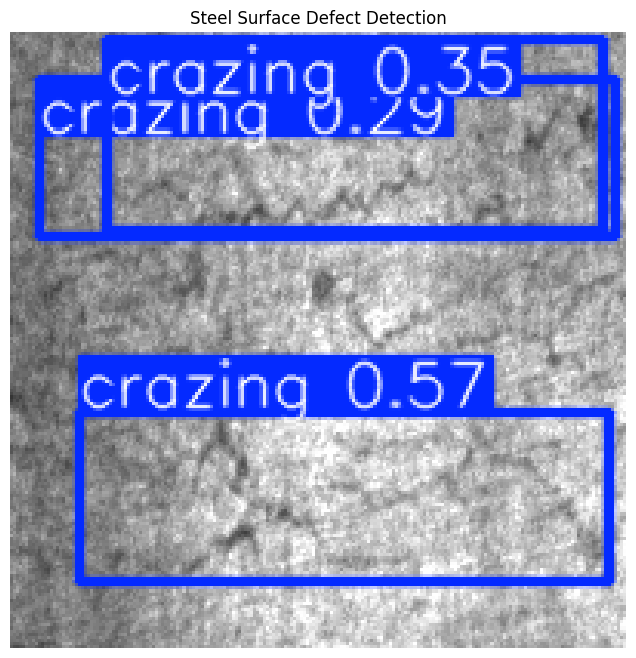

In [ ]:
import matplotlib.pyplot as plt

result = prediction[0]

plt.figure(figsize=(10, 8))
plt.imshow(result.plot()[..., ::-1])
plt.axis("off")
plt.title("Steel Surface Defect Detection")
plt.show()

In [ ]:
from pathlib import Path

dataset1_path = Path(
    "/content/drive/MyDrive/ML/datasets/dataset1_xml/NEU-DET"
)

train_images_path = dataset1_path / "train" / "images"
val_images_path = dataset1_path / "validation" / "images"

image_extensions = {".jpg", ".jpeg", ".png", ".bmp"}

train_images = [
    file for file in train_images_path.rglob("*")
    if file.suffix.lower() in image_extensions
]

val_images = [
    file for file in val_images_path.rglob("*")
    if file.suffix.lower() in image_extensions
]

print("Training images:", len(train_images))
print("Validation images:", len(val_images))

print("\nFirst 10 training image paths:")

for image in train_images[:10]:
    print(image)

Training images: 1440
Validation images: 360

First 10 training image paths:
/content/drive/MyDrive/ML/datasets/dataset1_xml/NEU-DET/train/images/patches/patches_112.jpg
/content/drive/MyDrive/ML/datasets/dataset1_xml/NEU-DET/train/images/patches/patches_129.jpg
/content/drive/MyDrive/ML/datasets/dataset1_xml/NEU-DET/train/images/patches/patches_111.jpg
/content/drive/MyDrive/ML/datasets/dataset1_xml/NEU-DET/train/images/patches/patches_192.jpg
/content/drive/MyDrive/ML/datasets/dataset1_xml/NEU-DET/train/images/patches/patches_2.jpg
/content/drive/MyDrive/ML/datasets/dataset1_xml/NEU-DET/train/images/patches/patches_176.jpg
/content/drive/MyDrive/ML/datasets/dataset1_xml/NEU-DET/train/images/patches/patches_17.jpg
/content/drive/MyDrive/ML/datasets/dataset1_xml/NEU-DET/train/images/patches/patches_15.jpg
/content/drive/MyDrive/ML/datasets/dataset1_xml/NEU-DET/train/images/patches/patches_158.jpg
/content/drive/MyDrive/ML/datasets/dataset1_xml/NEU-DET/train/images/patches/patches_18.jp

In [ ]:
from pathlib import Path

xml_path = dataset1_path / "train" / "annotations"

xml_files = list(xml_path.glob("*.xml"))

print("XML files:", len(xml_files))

if xml_files:
    print("\nExample XML file:")
    print(xml_files[0].read_text()[:2000])

XML files: 1440

Example XML file:
<annotation>
	<folder>in</folder>
	<filename>inclusion_63.jpg</filename>
	<source>
		<database>NEU-DET</database>
	</source>
	<size>
		<width>200</width>
		<height>200</height>
		<depth>1</depth>
	</size>
	<segmented>0</segmented>
	<object>
		<name>inclusion</name>
		<pose>Unspecified</pose>
		<truncated>0</truncated>
		<difficult>0</difficult>
		<bndbox>
			<xmin>143</xmin>
			<ymin>41</ymin>
			<xmax>168</xmax>
			<ymax>116</ymax>
		</bndbox>
	</object>
	<object>
		<name>inclusion</name>
		<pose>Unspecified</pose>
		<truncated>0</truncated>
		<difficult>0</difficult>
		<bndbox>
			<xmin>147</xmin>
			<ymin>108</ymin>
			<xmax>164</xmax>
			<ymax>179</ymax>
		</bndbox>
	</object>
</annotation>

